### Critical levels for the \(S\)-statistic with iterative inpainting

#### Unfiltered and filtered antipodal searches

For both searches, each topology simulation or null realisation is processed through the same pipeline:

$$
\begin{aligned}
&\text{Topology CMB simulation or null CMB realisation}
\\
&\qquad\downarrow
\\
&\text{Add foreground emission}
\\
&\qquad\downarrow
\\
&\text{Apply beam and instrumental noise}
\\
&\qquad\downarrow
\\
&\text{ILC component separation}
\\
&\qquad\downarrow
\\
&\text{Apply Galactic mask}.
\end{aligned}
$$

The masked region is then iteratively inpainted:

$$
\begin{aligned}
&\text{Masked map}
\\
&\qquad\downarrow
\\
&\text{Gaussian initial fill inside the mask}
\\
&\qquad\downarrow
\\
&\mathrm{map}\rightarrow a_{\ell m}\rightarrow\mathrm{map}
\\
&\qquad\downarrow
\\
&\text{Restore the observed pixels outside the mask}
\\
&\qquad\downarrow
\\
&\text{Repeat for 50 iterations}.
\end{aligned}
$$

The resulting inpainted map is used in two separate antipodal circle searches:

- **Unfiltered search:** calculate the \(S\)-statistic directly from the inpainted map.
- **Filtered search:** apply the chosen harmonic-space filter before calculating the \(S\)-statistic.

The critical levels are determined separately for the unfiltered and filtered searches from the corresponding null distributions of \(S_{\max}(\alpha)\).

Filtered:
  alpha = alpha_deg
  95.4% = S_crit_filtered_95p4
  99.7% = S_crit_filtered_99p7

Unfiltered:
  alpha = alpha_deg
  95.4% = S_crit_filtered_95p4
  99.7% = S_crit_filtered_99p7


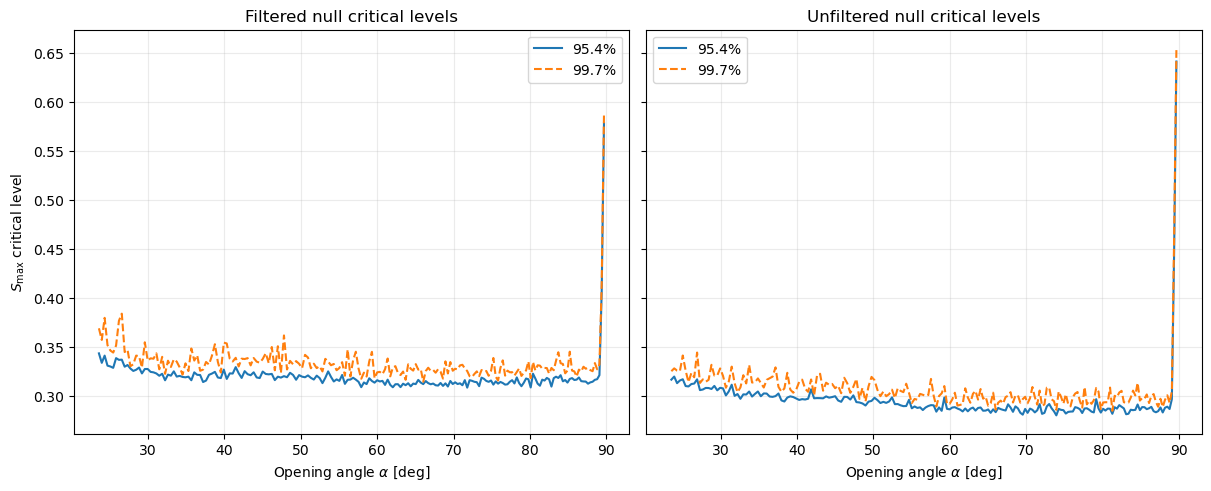

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# ==================================================
# Saved null S-statistic critical levels
# ==================================================

base = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

filtered_file = (
    base
    / "null_ipf_filtered_S_critical"
    / "S_critical_filtered_95p4_99p7_by_alpha.dat"
)

unfiltered_file = (
    base
    / "null_unfiltered_S_critical"
    / "S_critical_unfiltered_95p4_99p7_by_alpha.dat"
)


# ==================================================
# Load saved critical levels
# ==================================================

filtered = pd.read_csv(
    filtered_file,
    sep=r"\s+",
)

unfiltered = pd.read_csv(
    unfiltered_file,
    sep=r"\s+",
)


# ==================================================
# Identify the critical-level columns from headers
# ==================================================

def find_column(
    table,
    required_strings,
):

    matches = []

    for column in table.columns:

        name = column.lower()

        if all(
            text.lower() in name
            for text in required_strings
        ):
            matches.append(column)

    if len(matches) != 1:
        raise RuntimeError(
            "Could not uniquely identify column "
            f"containing {required_strings}.\n"
            f"Available columns: "
            f"{list(table.columns)}"
        )

    return matches[0]


alpha_filtered_column = find_column(
    filtered,
    ["alpha"],
)

cl95_filtered_column = find_column(
    filtered,
    ["95", "4"],
)

cl997_filtered_column = find_column(
    filtered,
    ["99", "7"],
)

alpha_unfiltered_column = find_column(
    unfiltered,
    ["alpha"],
)

cl95_unfiltered_column = find_column(
    unfiltered,
    ["95", "4"],
)

cl997_unfiltered_column = find_column(
    unfiltered,
    ["99", "7"],
)


# ==================================================
# Extract curves
# ==================================================

alpha_filtered = (
    filtered[
        alpha_filtered_column
    ]
    .to_numpy()
)

cl95_filtered = (
    filtered[
        cl95_filtered_column
    ]
    .to_numpy()
)

cl997_filtered = (
    filtered[
        cl997_filtered_column
    ]
    .to_numpy()
)

alpha_unfiltered = (
    unfiltered[
        alpha_unfiltered_column
    ]
    .to_numpy()
)

cl95_unfiltered = (
    unfiltered[
        cl95_unfiltered_column
    ]
    .to_numpy()
)

cl997_unfiltered = (
    unfiltered[
        cl997_unfiltered_column
    ]
    .to_numpy()
)


# ==================================================
# Confirm which columns are being used
# ==================================================

print(
    "Filtered:"
)

print(
    "  alpha =",
    alpha_filtered_column,
)

print(
    "  95.4% =",
    cl95_filtered_column,
)

print(
    "  99.7% =",
    cl997_filtered_column,
)

print(
    "\nUnfiltered:"
)

print(
    "  alpha =",
    alpha_unfiltered_column,
)

print(
    "  95.4% =",
    cl95_unfiltered_column,
)

print(
    "  99.7% =",
    cl997_unfiltered_column,
)


# ==================================================
# Plot
# ==================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.8),
    sharey=True,
    constrained_layout=True,
)


# --------------------------------------------------
# Filtered
# --------------------------------------------------

axes[0].plot(
    alpha_filtered,
    cl95_filtered,
    label="95.4%",
)

axes[0].plot(
    alpha_filtered,
    cl997_filtered,
    linestyle="--",
    label="99.7%",
)

axes[0].set_xlabel(
    r"Opening angle $\alpha$ [deg]"
)

axes[0].set_ylabel(
    r"$S_{\max}$ critical level"
)

axes[0].set_title(
    "Filtered null critical levels"
)

axes[0].grid(
    alpha=0.25
)

axes[0].legend()


# --------------------------------------------------
# Unfiltered
# --------------------------------------------------

axes[1].plot(
    alpha_unfiltered,
    cl95_unfiltered,
    label="95.4%",
)

axes[1].plot(
    alpha_unfiltered,
    cl997_unfiltered,
    linestyle="--",
    label="99.7%",
)

axes[1].set_xlabel(
    r"Opening angle $\alpha$ [deg]"
)

axes[1].set_title(
    "Unfiltered null critical levels"
)

axes[1].grid(
    alpha=0.25
)

axes[1].legend()


plt.show()

### Filtered $D(\beta_S)$ Null Critical Levels

The 95.4% and 99.7% null critical levels of the filtered $D$-statistic are shown as functions of opening angle $\alpha$.

Here, $D$ is evaluated at the geometry

$$
(i_S,\; j_S,\; \beta_S),
$$

selected by the corresponding $S$-statistic search.

95.4% column: D_floor_filtered_95p4
99.7% column: D_floor_filtered_99p7


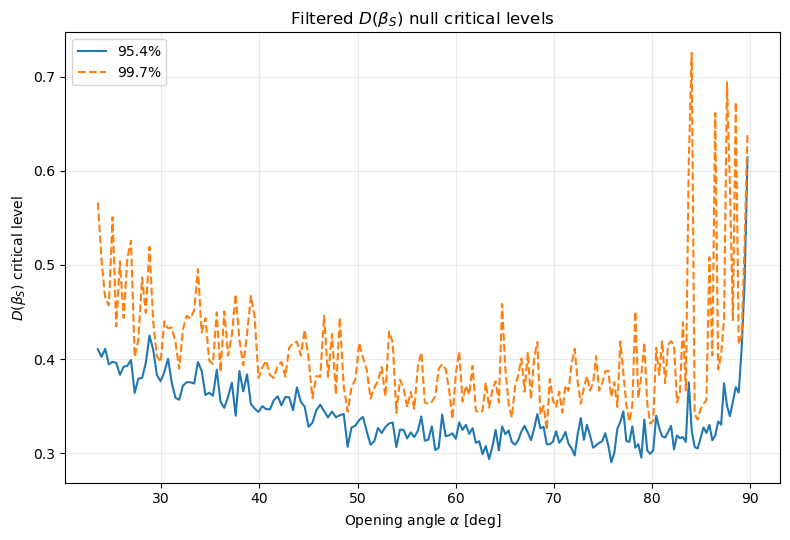

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# ==================================================
# Saved filtered D critical levels
# ==================================================

d_floor_file = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
    "/null_ipf_filtered_D_at_S_plots"
    "/D_floor_filtered_95p4_99p7_by_alpha.dat"
)


# ==================================================
# Load saved critical levels
# ==================================================

d_floor = pd.read_csv(
    d_floor_file,
    sep=r"\s+",
)


# ==================================================
# Identify columns
# ==================================================

def find_column(
    table,
    required_strings,
):

    matches = []

    for column in table.columns:

        name = column.lower()

        if all(
            text.lower() in name
            for text in required_strings
        ):
            matches.append(column)

    if len(matches) != 1:
        raise RuntimeError(
            f"Could not identify {required_strings}.\n"
            f"Available columns: {list(table.columns)}"
        )

    return matches[0]


alpha_column = find_column(
    d_floor,
    ["alpha"],
)

d95_column = find_column(
    d_floor,
    ["95", "4"],
)

d997_column = find_column(
    d_floor,
    ["99", "7"],
)


alpha = d_floor[
    alpha_column
].to_numpy()

d95 = d_floor[
    d95_column
].to_numpy()

d997 = d_floor[
    d997_column
].to_numpy()


print(
    "95.4% column:",
    d95_column,
)

print(
    "99.7% column:",
    d997_column,
)


# ==================================================
# Plot
# ==================================================

plt.figure(
    figsize=(8, 5.5)
)

plt.plot(
    alpha,
    d95,
    label="95.4%",
)

plt.plot(
    alpha,
    d997,
    linestyle="--",
    label="99.7%",
)

plt.xlabel(
    r"Opening angle $\alpha$ [deg]"
)

plt.ylabel(
    r"$D(\beta_S)$ critical level"
)

plt.title(
    r"Filtered $D(\beta_S)$ null critical levels"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.show()

### Generation of injected matched-circle maps

The code generates one Gaussian CMB background and injects an antipodal orientable matched-circle pair.

The fixed settings are

$$
N_{\mathrm{side}}=512,
\qquad
\ell_{\max}=800,
\qquad
N_{\phi}=512,
\qquad
\alpha=50.1616^\circ,
\qquad
\beta_{\mathrm{inj}}=0.
$$

#### Step 1: Generate the Gaussian CMB background

The Planck spectrum $D_\ell$ is converted from $\mu\mathrm{K}^2$ to $C_\ell$ in $\mathrm{K}^2$:

$$
C_\ell
=
D_\ell\,10^{-12}
\frac{2\pi}{\ell(\ell+1)}.
$$

A Gaussian CMB map is then generated from $C_\ell$. The same background map is used for every injection position.

#### Step 2: Define an antipodal circle pair

For each chosen position, the source centre is moved to the nearest $N_{\mathrm{side}}=128$ HEALPix centre used by the circle search.

The target centre is chosen as the nearest search-grid point to the antipode:

$$
\hat{\boldsymbol n}_j
\approx
-\hat{\boldsymbol n}_i.
$$

Only pairs satisfying

$$
\Delta\theta_{ij}\geq179^\circ
$$

are retained.

#### Step 3: Sample the source circle

The background temperature is sampled at $N_\phi$ equally spaced points around the source circle:

$$
x_k
=
T_{\mathrm{bg}}
\left(
\hat{\boldsymbol r}_i(\varphi_k)
\right),
\qquad
\varphi_k
=
\frac{2\pi k}{N_\phi}.
$$

#### Step 4: Construct and inject the matched circle

For the orientable matching, the target-circle profile is

$$
y_k
=
x_{(-k+\beta_{\mathrm{inj}})\bmod N_\phi}.
$$

Since $\beta_{\mathrm{inj}}=0$,

$$
y_k
=
x_{(-k)\bmod N_\phi}.
$$

This reversed source profile is painted as a thin, cosine-tapered ring around the target centre.

#### Step 5: Validate the injection

The injected target ring is resampled and compared with the expected target profile using

$$
D(\beta_{\mathrm{inj}})
=
\frac{
2\sum_k
y_k^{\mathrm{expected}}
y_k^{\mathrm{measured}}
}{
\sum_k
\left[
\left(y_k^{\mathrm{expected}}\right)^2
+
\left(y_k^{\mathrm{measured}}\right)^2
\right]
}.
$$

A successful injection should give

$$
D(\beta_{\mathrm{inj}})
\approx 1.
$$

/tmp/ipykernel_277431/774990978.py:102: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  background_map = hp.synfast(
setting the output map dtype to [dtype('float64')]


Injected search-grid geometry
  source pixel: 41756
  target pixel: 154652
  source seed offset [deg]: 0.05615043764036596
  target antipode offset [deg]: 0.0
  centre separation [deg]: 180.0
  opening angle [deg]: 50.16156154763937

Injection check
phase_bin = 0
reverse = True
ring_corr = 0.998393928761141
ring_rms_error [K] = 7.053606205778317e-06
D_at_injected_beta = 0.9974478225247492


setting the output map dtype to [dtype('float64')]


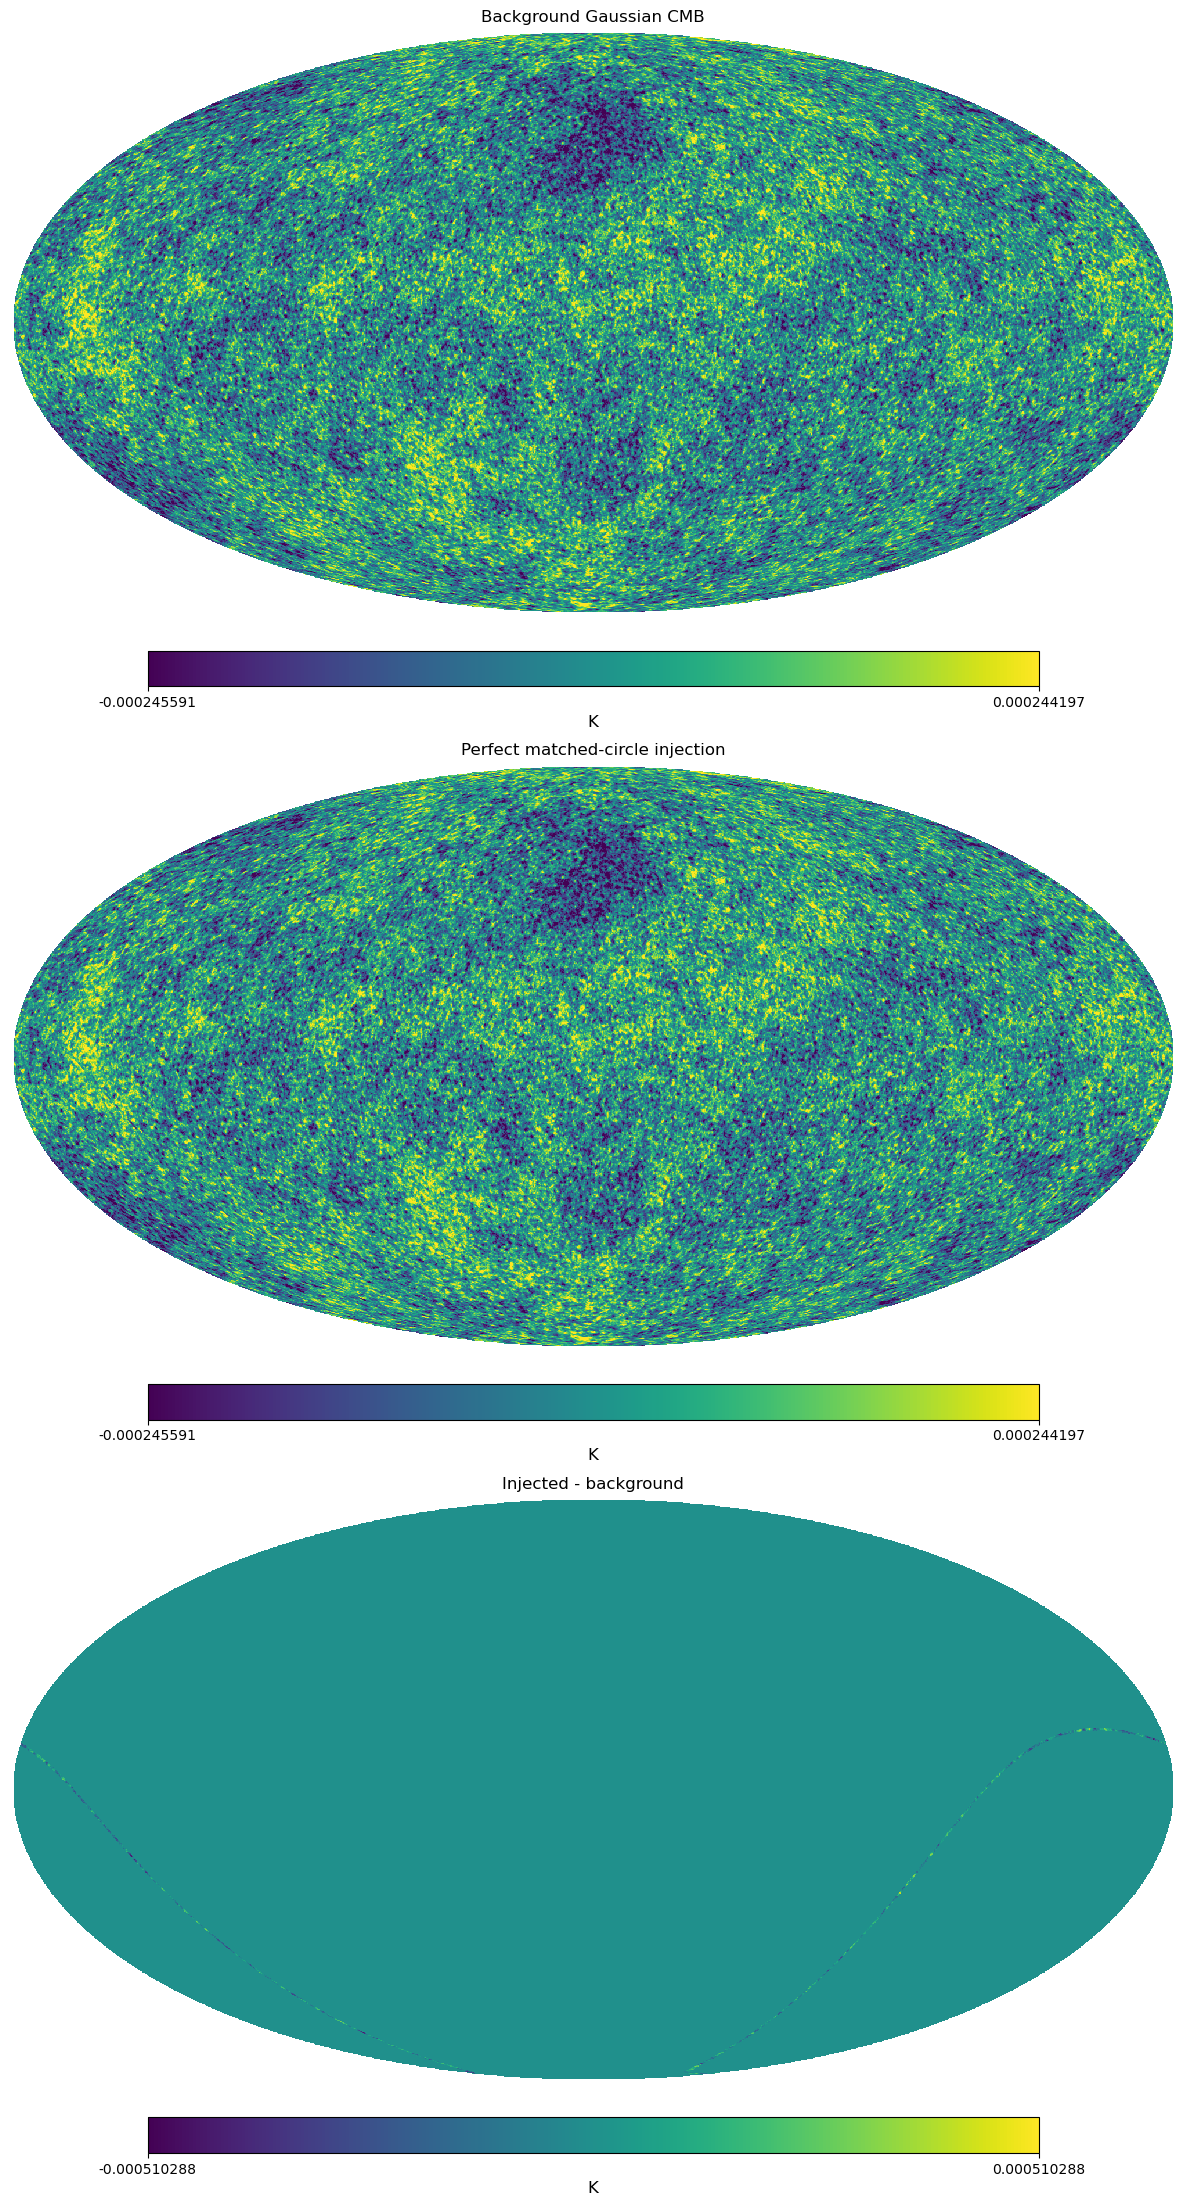


Saved:
/hydrarepo/xluo/circles-in-the-sky/perfect_injection_nside512_lmax800/background_map.fits
/hydrarepo/xluo/circles-in-the-sky/perfect_injection_nside512_lmax800/perfect_injection_full.fits
/hydrarepo/xluo/circles-in-the-sky/perfect_injection_nside512_lmax800/perfect_injection_check.png


In [2]:
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np


# ==================================================
# Configuration
# ==================================================

base = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

power_spectrum_file = (
    base
    / "src"
    / "COM_PowerSpect_CMB-TT-full_R3.01.txt"
)

output_dir = (
    base
    / "perfect_injection_nside512_lmax800"
)

output_dir.mkdir(
    exist_ok=True
)


# Map settings.
NSIDE = 512
NSIDE_SEARCH = 128
LMAX = 800
NPHI = 512

SEED = 12345


# Injected circle settings.
ALPHA_DEG = 50.16156154763937

THETA_I_DEG = 55.0
PHI_I_DEG = 20.0

PHASE_BIN = 0
REVERSE = True


# ==================================================
# Load Planck TT spectrum
# D_ell [microK^2] -> C_ell [K^2]
# ==================================================

spectrum = np.loadtxt(
    power_spectrum_file,
    comments="#",
)

ell = (
    spectrum[:, 0]
    .astype(int)
)

Dl_microK2 = spectrum[:, 1]

cl = np.zeros(
    LMAX + 1,
    dtype=float,
)

for l, Dl in zip(
    ell,
    Dl_microK2,
):

    if 2 <= l <= LMAX:

        cl[l] = (
            Dl
            * 1.0e-12
            * 2.0
            * np.pi
            / (
                l
                * (l + 1.0)
            )
        )

cl[:2] = 0.0


# ==================================================
# Generate Gaussian CMB background
# ==================================================

np.random.seed(
    SEED
)

background_map = hp.synfast(
    cl,
    nside=NSIDE,
    lmax=LMAX,
    pixwin=False,
    new=True,
    verbose=False,
)


# ==================================================
# Geometry helpers
# ==================================================

def make_basis(
    centre,
):
    """
    Return two orthogonal tangent vectors at centre.
    """

    centre = np.asarray(
        centre,
        dtype=float,
    )

    centre /= np.linalg.norm(
        centre
    )

    reference = np.array(
        [0.0, 0.0, 1.0]
    )

    if abs(
        np.dot(
            reference,
            centre,
        )
    ) > 0.9:

        reference = np.array(
            [1.0, 0.0, 0.0]
        )

    e1 = (
        reference
        - np.dot(
            reference,
            centre,
        )
        * centre
    )

    e1 /= np.linalg.norm(
        e1
    )

    e2 = np.cross(
        centre,
        e1,
    )

    return e1, e2


def circle_vectors(
    centre,
    alpha,
    phi,
):
    """
    Return unit vectors along a circle.
    """

    e1, e2 = make_basis(
        centre
    )

    return (
        np.cos(alpha)
        * centre[:, None]
        + np.sin(alpha)
        * (
            np.cos(phi)[None, :]
            * e1[:, None]
            + np.sin(phi)[None, :]
            * e2[:, None]
        )
    )


def sample_circle(
    sky_map,
    centre,
    alpha,
    nphi,
):
    """
    Sample a circle using HEALPix interpolation.
    """

    phi = (
        2.0
        * np.pi
        * np.arange(nphi)
        / nphi
    )

    vectors = circle_vectors(
        centre,
        alpha,
        phi,
    )

    theta = np.arccos(
        np.clip(
            vectors[2],
            -1.0,
            1.0,
        )
    )

    longitude = np.mod(
        np.arctan2(
            vectors[1],
            vectors[0],
        ),
        2.0 * np.pi,
    )

    return hp.get_interp_val(
        sky_map,
        theta,
        longitude,
    )


def periodic_profile(
    profile,
    phi,
):
    """
    Periodically interpolate a ring profile.
    """

    nphi = len(
        profile
    )

    u = (
        np.mod(
            phi,
            2.0 * np.pi,
        )
        * nphi
        / (
            2.0
            * np.pi
        )
    )

    k0 = (
        np.floor(u)
        .astype(int)
        % nphi
    )

    fraction = (
        u
        - np.floor(u)
    )

    k1 = (
        k0 + 1
    ) % nphi

    return (
        (1.0 - fraction)
        * profile[k0]
        + fraction
        * profile[k1]
    )


def paint_circle(
    sky_map,
    centre,
    alpha,
    profile,
    nside,
):
    """
    Paint a thin smooth annulus carrying the ring profile.
    """

    output = sky_map.copy()

    pixel_size = np.sqrt(
        hp.nside2pixarea(
            nside
        )
    )

    core_halfwidth = (
        2.0
        * pixel_size
    )

    taper_width = (
        1.0
        * pixel_size
    )

    outer_halfwidth = (
        core_halfwidth
        + taper_width
    )

    pixels = hp.query_disc(
        nside,
        centre,
        alpha + outer_halfwidth,
        inclusive=True,
    )

    vectors = np.asarray(
        hp.pix2vec(
            nside,
            pixels,
        ),
        dtype=float,
    )

    cos_rho = np.clip(
        np.dot(
            centre,
            vectors,
        ),
        -1.0,
        1.0,
    )

    rho = np.arccos(
        cos_rho
    )

    distance_from_ring = np.abs(
        rho - alpha
    )

    keep = (
        distance_from_ring
        < outer_halfwidth
    )

    pixels = pixels[
        keep
    ]

    vectors = vectors[
        :,
        keep,
    ]

    cos_rho = cos_rho[
        keep
    ]

    distance_from_ring = (
        distance_from_ring[
            keep
        ]
    )

    e1, e2 = make_basis(
        centre
    )

    radial = (
        vectors
        - centre[:, None]
        * cos_rho[None, :]
    )

    radial /= np.linalg.norm(
        radial,
        axis=0,
    )[None, :]

    local_phi = np.mod(
        np.arctan2(
            np.dot(
                e2,
                radial,
            ),
            np.dot(
                e1,
                radial,
            ),
        ),
        2.0 * np.pi,
    )

    desired = periodic_profile(
        profile,
        local_phi,
    )

    weight = np.zeros(
        len(pixels)
    )

    core = (
        distance_from_ring
        <= core_halfwidth
    )

    taper = (
        (
            distance_from_ring
            > core_halfwidth
        )
        & (
            distance_from_ring
            < outer_halfwidth
        )
    )

    weight[
        core
    ] = 1.0

    t = (
        (
            distance_from_ring[
                taper
            ]
            - core_halfwidth
        )
        / taper_width
    )

    weight[
        taper
    ] = (
        0.5
        * (
            1.0
            + np.cos(
                np.pi * t
            )
        )
    )

    output[
        pixels
    ] = (
        (
            1.0
            - weight
        )
        * output[
            pixels
        ]
        + weight
        * desired
    )

    return output


# ==================================================
# Snap injection to the search grid
# ==================================================

search_pixels = np.arange(
    hp.nside2npix(
        NSIDE_SEARCH
    )
)

search_vectors = np.asarray(
    hp.pix2vec(
        NSIDE_SEARCH,
        search_pixels,
    ),
    dtype=float,
)


def snap_to_search_grid(
    direction,
):
    """
    Return the nearest Nside=128 HEALPix centre.
    """

    dots = np.dot(
        direction,
        search_vectors,
    )

    pixel = int(
        np.argmax(dots)
    )

    centre = (
        search_vectors[
            :,
            pixel
        ]
    )

    offset_deg = np.rad2deg(
        np.arccos(
            np.clip(
                dots[pixel],
                -1.0,
                1.0,
            )
        )
    )

    return (
        pixel,
        centre,
        offset_deg,
    )


# ==================================================
# Define one perfect antipodal pair
# ==================================================

alpha = np.deg2rad(
    ALPHA_DEG
)

seed_centre_i = np.asarray(
    hp.ang2vec(
        np.deg2rad(
            THETA_I_DEG
        ),
        np.deg2rad(
            PHI_I_DEG
        ),
    ),
    dtype=float,
)

pix_i_search, centre_i, offset_i_deg = (
    snap_to_search_grid(
        seed_centre_i
    )
)

desired_centre_j = (
    -centre_i
)

pix_j_search, centre_j, offset_j_deg = (
    snap_to_search_grid(
        desired_centre_j
    )
)

actual_sep_deg = np.rad2deg(
    np.arccos(
        np.clip(
            np.dot(
                centre_i,
                centre_j,
            ),
            -1.0,
            1.0,
        )
    )
)

if actual_sep_deg < 179.0:

    raise ValueError(
        "Injected pair does not pass "
        "min_separation_angle = 179.0"
    )


print(
    "Injected search-grid geometry"
)

print(
    "  source pixel:",
    pix_i_search,
)

print(
    "  target pixel:",
    pix_j_search,
)

print(
    "  source seed offset [deg]:",
    offset_i_deg,
)

print(
    "  target antipode offset [deg]:",
    offset_j_deg,
)

print(
    "  centre separation [deg]:",
    actual_sep_deg,
)

print(
    "  opening angle [deg]:",
    ALPHA_DEG,
)


# ==================================================
# Source-circle profile
# ==================================================

source_profile = sample_circle(
    background_map,
    centre_i,
    alpha,
    NPHI,
)


# ==================================================
# Construct perfectly matched target profile
# ==================================================

k = np.arange(
    NPHI
)

if REVERSE:

    target_indices = (
        -k
        + PHASE_BIN
    ) % NPHI

else:

    target_indices = (
        k
        + PHASE_BIN
    ) % NPHI


target_profile = (
    source_profile[
        target_indices
    ]
)


# ==================================================
# Inject target circle
# ==================================================

injected_map = paint_circle(
    background_map,
    centre_j,
    alpha,
    target_profile,
    NSIDE,
)


# ==================================================
# Validate injection
# ==================================================

source_after = sample_circle(
    injected_map,
    centre_i,
    alpha,
    NPHI,
)

target_after = sample_circle(
    injected_map,
    centre_j,
    alpha,
    NPHI,
)

expected_target = (
    source_after[
        target_indices
    ]
)

ring_rms_error = np.sqrt(
    np.mean(
        (
            target_after
            - expected_target
        ) ** 2
    )
)

x0 = (
    expected_target
    - np.mean(
        expected_target
    )
)

y0 = (
    target_after
    - np.mean(
        target_after
    )
)

ring_corr = (
    np.dot(
        x0,
        y0,
    )
    / np.sqrt(
        np.dot(
            x0,
            x0,
        )
        * np.dot(
            y0,
            y0,
        )
    )
)

d_denominator = np.sum(
    expected_target**2
    + target_after**2
)

d_at_injected_beta = (
    np.nan
    if d_denominator == 0.0
    else (
        2.0
        * np.sum(
            expected_target
            * target_after
        )
        / d_denominator
    )
)


print(
    "\nInjection check"
)

print(
    "phase_bin =",
    PHASE_BIN,
)

print(
    "reverse =",
    REVERSE,
)

print(
    "ring_corr =",
    ring_corr,
)

print(
    "ring_rms_error [K] =",
    ring_rms_error,
)

print(
    "D_at_injected_beta =",
    d_at_injected_beta,
)


# ==================================================
# Save maps
# ==================================================

background_file = (
    output_dir
    / "background_map.fits"
)

injected_file = (
    output_dir
    / "perfect_injection_full.fits"
)

hp.write_map(
    background_file,
    background_map,
    overwrite=True,
)

hp.write_map(
    injected_file,
    injected_map,
    overwrite=True,
)


# ==================================================
# Visualise injection
# ==================================================

delta_map = (
    injected_map
    - background_map
)

map_min = np.percentile(
    background_map,
    1,
)

map_max = np.percentile(
    background_map,
    99,
)

delta_limit = np.max(
    np.abs(
        delta_map
    )
)


fig = plt.figure(
    figsize=(18, 22)
)

hp.mollview(
    background_map,
    fig=fig.number,
    sub=(3, 1, 1),
    title="Background Gaussian CMB",
    unit="K",
    min=map_min,
    max=map_max,
    xsize=2000,
)

hp.mollview(
    injected_map,
    fig=fig.number,
    sub=(3, 1, 2),
    title="Perfect matched-circle injection",
    unit="K",
    min=map_min,
    max=map_max,
    xsize=2000,
)

hp.mollview(
    delta_map,
    fig=fig.number,
    sub=(3, 1, 3),
    title="Injected - background",
    unit="K",
    min=-delta_limit,
    max=delta_limit,
    xsize=2000,
)

plot_file = (
    output_dir
    / "perfect_injection_check.png"
)

plt.savefig(
    plot_file,
    dpi=200,
)

plt.show()


print(
    "\nSaved:"
)

print(
    background_file
)

print(
    injected_file
)

print(
    plot_file
)